<div dir="rtl">

# نوت‌بوک ۷: خطر نشت اطلاعات و طرح تقسیم داده

**فاز ۱، تسک ۱۱**

سند دو چیز می‌خواهد که **قبل از آموزش هر مدلی** باید روشن شوند:

۱. **خطر نشت اطلاعات:** چه اطلاعاتی ممکن است مستقیم یا غیرمستقیم آینده یا خود جواب (امتیاز) را لو بدهد؟
۲. **واحد درست تقسیم داده:** و چرا تقسیم تصادفی ردیف‌ها ممکن است نتیجه را خوش‌بینانه نشان دهد.

**نشت اطلاعات** یعنی مدل در زمان آموزش یا ارزیابی به اطلاعاتی دسترسی داشته باشد که در دنیای واقعی، در لحظه‌ی پیش‌بینی، در دسترس نیست. نتیجه‌اش مدلی است که روی کاغذ عالی است و در عمل شکست می‌خورد.

این نوت‌بوک:
- فهرست کامل خطرهای نشت را با شواهد عددی می‌سازد،
- نشان می‌دهد تقسیم تصادفی چقدر اطلاعات آینده را وارد آموزش می‌کند،
- طرح تقسیم زمانی را تعریف و آمار هر بخش را گزارش می‌کند.

</div>

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from splits import assign_split
from text_utils import clean_text

cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"
REP = ROOT / "reports" / "phase1"
SEED = cfg["seed"]

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 110)
BAR, NEG = "#3B6EA8", "#B5523B"
SPLIT_COLORS = {"train": "#3B6EA8", "validation": "#8FB0D6", "test": "#B5523B"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

reviews = pd.read_parquet(PROC / "reviews_rc.parquet").drop_duplicates().reset_index(drop=True)
meta = pd.read_parquet(PROC / "meta_rc.parquet")
reviews["date"] = pd.to_datetime(reviews["timestamp"], unit="ms")
reviews["negative"] = reviews["rating"] <= 2
reviews["split"] = assign_split(reviews["date"], cfg)
print(reviews["split"].value_counts().to_string())

split
train           478426
test            156837
validation      142597
out_of_range     73889


<div dir="rtl">

## ۱. فهرست خطرهای نشت

هر ستونی که ممکن است به مدل داده شود را بررسی می‌کنیم. سؤال کلیدی برای هر ستون: **«آیا این اطلاعات در لحظه‌ای که نقد نوشته می‌شود (یا لحظه‌ی ساخت گزارش) در دسترس است؟»**

### ۱-۱. ستون‌هایی که از آینده خبر دارند

`average_rating` و `rating_number` محصول در **سال ۲۰۲۳** از صفحه‌ی محصول برداشته شده‌اند؛ یعنی میانگین **همه‌ی** نقدها، شامل نقدهای بعد از هر نقد. اگر مدل این را ببیند، عملاً امتیاز آینده را دیده است. ببینیم این ستون چقدر به امتیاز واقعی نقدهای همان محصول نزدیک است:

</div>

In [2]:
per_product = reviews.groupby("parent_asin")["rating"].agg(our_mean="mean", n="size")
check = meta.set_index("parent_asin")[["average_rating", "rating_number"]].join(per_product, how="inner")
check = check[check["n"] >= 20]
print(f"products with >= 20 reviews: {len(check):,}")
print(f"correlation between Amazon's average_rating and the mean of our reviews: "
      f"{check['average_rating'].corr(check['our_mean']):.2f}")
print()
print("If a model saw average_rating, it would partly 'see the answer'.")

products with >= 20 reviews: 6,746
correlation between Amazon's average_rating and the mean of our reviews: 0.67

If a model saw average_rating, it would partly 'see the answer'.


<div dir="rtl">

### ۱-۲. ستون‌هایی که بعد از نقد ساخته می‌شوند

`helpful_vote` (رأی «مفید بود») بعد از انتشار نقد جمع می‌شود. نقدی که امروز نوشته شده هنوز رأیی ندارد. نقدهای قدیمی‌تر فرصت بیشتری برای جمع کردن رأی داشته‌اند:

</div>

In [4]:
hv = reviews.groupby(reviews["date"].dt.year)["helpful_vote"].mean().loc[2015:2023].round(2)
hv.to_frame("mean helpful votes").T

date,2015,2016,2017,2018,2019,2020,2021,2022,2023
mean helpful votes,1.27,1.23,1.12,1.32,1.11,1.0,0.8,0.61,0.26


<div dir="rtl">

### ۱-۳. ویژگی‌هایی که اگر روی کل تاریخ حساب شوند، نشت دارند

«تعداد نقد محصول» اگر روی کل داده شمرده شود، نقدهای آینده را هم شامل می‌شود. در نوت‌بوک ۵ دیدیم پرفروش‌ترین محصولات کمتر شکایت دارند؛ پس این عدد به امتیاز مربوط است و نشت آن مهم است. **راه درست:** فقط نقدهای **قبل از** لحظه‌ی پیش‌بینی شمرده شوند.

### ۱-۴. نشت پنهان: قیمت و «نداشتن قیمت»

قیمت هم در ۲۰۲۳ برداشته شده است. در نوت‌بوک ۳ فرض کردیم محصولات بی‌قیمت احتمالاً همان‌هایی‌اند که تا ۲۰۲۳ از فروش خارج شده‌اند. اگر این درست باشد، «نداشتن قیمت» اطلاعاتی درباره‌ی **آینده‌ی محصول** دارد. این نشت ضعیف‌تری است، ولی باید با آزمایش **با و بدون ویژگی‌های قیمت** (ablation) در فاز ۳ سنجیده شود.

### ۱-۵. نشت از راه متن تکراری

در نوت‌بوک ۲ دیدیم بعضی کاربران یک متن را برای چند محصول کپی کرده‌اند و بعضی متن‌ها از کاربران مختلف عیناً تکرار شده‌اند. اگر یک نسخه در آموزش و نسخه‌ی دیگر در آزمون باشد، مدل جواب را از قبل حفظ کرده است. این را در بخش ۳ می‌سنجیم.

### ۱-۶. نشت در پیش‌پردازش

هر چیزی که از داده **یاد گرفته می‌شود** (واژه‌نامه‌ی متن، نرمال‌سازی قیمت، خوشه‌بندی جنبه‌ها در فاز ۲) باید **فقط روی داده‌ی آموزش** ساخته شود و بعد روی اعتبارسنجی و آزمون اعمال شود.

</div>

<div dir="rtl">

## ۲. چرا تقسیم تصادفی خوش‌بینانه است؟

در تقسیم تصادفی، هر نقد بدون توجه به زمان به آموزش یا آزمون می‌رود. برای نقدهای آزمون می‌پرسیم: **چند درصدشان محصولی دارند که در داده‌ی آموزش، نقدهای «بعد از» آن‌ها هم وجود دارد؟** یعنی مدل هنگام آموزش، آینده‌ی همان محصول را دیده است.

</div>

In [6]:
in_range = reviews[reviews["split"] != "out_of_range"].copy()
rng = np.random.default_rng(SEED)
in_range["random_split"] = np.where(rng.random(len(in_range)) < 0.8, "train", "test")

def future_seen(df, split_col):
    train = df[df[split_col] == "train"]
    test = df[df[split_col] == "test"]
    last_train_time = train.groupby("parent_asin")["timestamp"].max()
    lt = test["parent_asin"].map(last_train_time)
    return (lt > test["timestamp"]).mean()

temporal = in_range.assign(t_split=np.where(in_range["split"] == "test", "test", "train"))
comparison = pd.DataFrame({
    "random 80/20": [future_seen(in_range, "random_split")],
    "temporal (ours)": [future_seen(temporal, "t_split")],
}, index=["% of test reviews whose product's FUTURE is in training"]).map(lambda v: f"{100 * v:.1f}%")
comparison

,random 80/20,temporal (ours)
% of test reviews whose product's FUTURE is in training,90.2%,0.0%


<div dir="rtl">

در تقسیم تصادفی، برای بخش بزرگی از نقدهای آزمون، مدل نقدهای **بعدی** همان محصول را در آموزش دیده است. در دنیای واقعی هیچ‌وقت چنین اطلاعاتی نداریم؛ صاحب محصول همیشه با گذشته، آینده را پیش‌بینی می‌کند. در تقسیم زمانی این عدد به‌طور ساختاری صفر است.

همچنین در نوت‌بوک ۵ دیدیم سهم نقدهای منفی در طول زمان عوض شده است. تقسیم تصادفی این تغییر را **پنهان** می‌کند، چون آموزش و آزمون از همه‌ی سال‌ها نمونه می‌گیرند؛ تقسیم زمانی آن را **نشان می‌دهد**، همان‌طور که در استفاده‌ی واقعی رخ می‌دهد.

</div>

<div dir="rtl">

## ۳. طرح تقسیم زمانی

بازه‌ی تحلیل (ژانویه‌ی ۲۰۱۵ تا مارس ۲۰۲۳، تصمیم تسک ۱۰) به سه بخش پشت سر هم تقسیم می‌شود. مرزها روی ابتدای بازه‌های ۳ ماهه‌اند تا هیچ بازه‌ای دو تکه نشود. مرزها در `configs/config.yaml` (بخش `split`) و تابع تقسیم در `src/splits.py` تعریف شده‌اند تا همه‌ی فازها دقیقاً از همین تقسیم استفاده کنند.

| بخش | بازه | کاربرد |
|---|---|---|
| **آموزش** | ژانویه‌ی ۲۰۱۵ تا دسامبر ۲۰۲۰ | ساخت مدل و هر چیزی که از داده یاد گرفته می‌شود |
| **اعتبارسنجی** | ژانویه تا دسامبر ۲۰۲۱ | انتخاب مدل و تنظیم پارامترها |
| **آزمون** | ژانویه‌ی ۲۰۲۲ تا مارس ۲۰۲۳ | **فقط یک بار**، در پایان فاز ۳؛ هیچ تنظیمی بر اساس آن انجام نمی‌شود |

</div>

In [8]:
K = cfg["window"]["min_reviews"]
months = cfg["window"]["months"]
mi = in_range["date"].dt.year * 12 + in_range["date"].dt.month - 1
in_range["window"] = (mi // months) * months
units = in_range.groupby(["split", "parent_asin", "window"]).size().rename("n").reset_index()

order = ["train", "validation", "test"]
split_summary = pd.DataFrame({
    "from": in_range.groupby("split")["date"].min().dt.date,
    "to": in_range.groupby("split")["date"].max().dt.date,
    "reviews": in_range.groupby("split").size(),
    "products": in_range.groupby("split")["parent_asin"].nunique(),
    f"report units (>= {K} reviews)": units[units["n"] >= K].groupby("split").size(),
    "negative_%": (100 * in_range.groupby("split")["negative"].mean()).round(1),
}).reindex(order)
split_summary["reviews_%"] = (100 * split_summary["reviews"] / split_summary["reviews"].sum()).round(1)
split_summary.to_csv(REP / "split_summary.csv")
split_summary

,from,to,reviews,products,report units (>= 20 reviews),negative_%,reviews_%
split,,,,,,,
train,2015-01-01,2020-12-31,478426,43642,3074,16.5,61.5
validation,2021-01-01,2021-12-31,142597,22496,912,20.5,18.3
test,2022-01-01,2023-03-31,156837,27434,1084,22.6,20.2


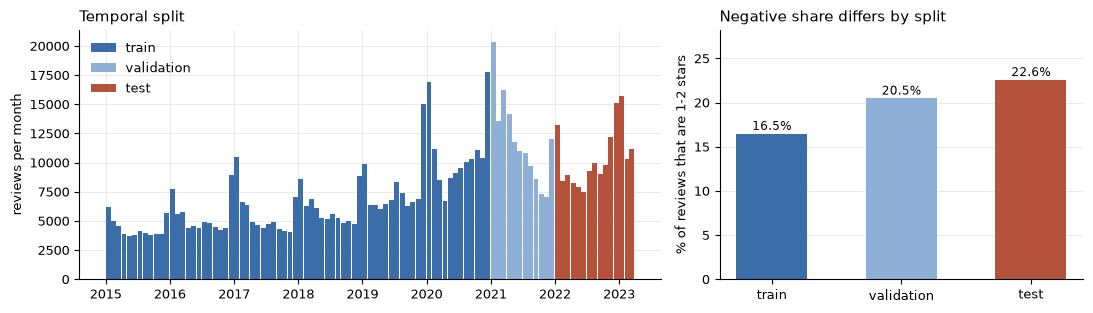

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.6, 1]})
monthly = in_range.set_index("date").groupby("split").resample("MS").size()
ax = axes[0]
for s in order:
    m = monthly.loc[s]
    ax.bar(m.index, m.values, width=28, color=SPLIT_COLORS[s], label=s, align="edge")
ax.set_ylabel("reviews per month")
ax.set_title("Temporal split", loc="left")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
ax.bar(order, split_summary["negative_%"], color=[SPLIT_COLORS[s] for s in order], width=0.55)
for i, v in enumerate(split_summary["negative_%"]):
    ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8.5)
ax.set_ylabel("% of reviews that are 1-2 stars")
ax.set_ylim(0, split_summary["negative_%"].max() * 1.25)
ax.set_title("Negative share differs by split", loc="left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(FIG / "fig15_temporal_split.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

## ۴. محصولات و متن‌های مشترک بین بخش‌ها

**محصولات مشترک:** بسیاری از محصولات آزمون در آموزش هم نقد دارند (البته نقدهای **قبلی**). این مجاز است و با کاربرد واقعی می‌خواند: صاحب محصولی که گزارش می‌خواهد، معمولاً سابقه‌ی نقد دارد. ولی خطرش این است که مدل به‌جای جنبه‌ها، **هویت محصول** را حفظ کند. برای سنجیدن این خطر، در فاز ۳ عملکرد را جداگانه روی **محصولات جدید** (بدون هیچ نقدی در آموزش) هم گزارش می‌کنیم.

**متن‌های تکراری:** چند نقد آزمون متنی دارند که عیناً در آموزش هم آمده است؟

</div>

In [11]:
train_products = set(in_range.loc[in_range["split"] == "train", "parent_asin"])
test = in_range[in_range["split"] == "test"]
new_products = ~test["parent_asin"].isin(train_products)
print(f"test reviews whose product also has (earlier) reviews in train: {(~new_products).mean():.1%}")
print(f"test reviews of NEW products (no review in train):                {new_products.mean():.1%} "
      f"({new_products.sum():,} reviews)")
print()

norm = lambda s: s.map(clean_text).str.lower()
train_texts = set(norm(in_range.loc[(in_range["split"] == "train") & (in_range["text"].str.len() > 50), "text"]))
test_long = test[test["text"].str.len() > 50]
same_text = norm(test_long["text"]).isin(train_texts)
print(f"test reviews (> 50 chars) whose exact text also appears in train: {same_text.sum():,} "
      f"({same_text.mean():.2%})")
print(test_long.loc[same_text, "text"].head(5).str[:110].to_string())

test reviews whose product also has (earlier) reviews in train: 41.3%
test reviews of NEW products (no review in train):                58.7% (92,037 reviews)

test reviews (> 50 chars) whose exact text also appears in train: 7 (0.01%)
49555                                                           It was a birthday present for my grandson. He loves it.
63522     I bought the car for my nephew for Christmas. He absolutely loves the car. It is a lot faster then I thoug...
283782    This thing is awesome! It is super durable and has survived many crashes into our furniture. Our furniture...
508127                                                         This was a Christmas gift for my grandson.  He loves it.
590027                                                       [[VIDEOID:3bb41a96ba88a92c10e5004906cd2bac]] Great product


<div dir="rtl">

## ۵. جدول خطرهای نشت و راهکار

این جدول در بند ۱۱ کارت پروژه و گزارش فاز ۱ می‌آید.

</div>

In [12]:
leak = pd.DataFrame([
    ("average_rating, rating_number (product)", "computed in 2023 from ALL reviews, incl. future ones",
     "never a model feature; used only for sanity checks"),
    ("helpful_vote", "collected after the review is published; older reviews have more",
     "never a model feature"),
    ("reviews per product (lifetime)", "counts future reviews; linked to rating (best-sellers less negative)",
     "if used, count only reviews BEFORE the prediction time"),
    ("price / price missing", "taken in 2023; missing price may mean 'discontinued later'",
     "use with care; phase-3 ablation with and without price features"),
    ("random row split", "test products' future reviews end up in training; hides drift over time",
     "temporal split (train 2015-2020, validation 2021, test 2022-2023Q1)"),
    ("duplicated / copied texts", "same text in train and test lets the model memorise the answer",
     "drop exact duplicates; check and report text overlap between splits"),
    ("fitting on all data", "vocabulary, scaling, aspect clusters learnt from test data",
     "fit every learnt step on train only, then apply to validation and test"),
    ("tuning on test", "choosing models or thresholds by test score",
     "test period locked; used once at the end of phase 3"),
    ("selecting units by outcome", "e.g. 'keep windows with >= 5 negative reviews' uses the label",
     "report-unit threshold uses review COUNT only (task 10)"),
], columns=["risk", "why it leaks", "safeguard"])
leak.to_csv(REP / "leakage_risks.csv", index=False)
leak

,risk,why it leaks,safeguard
0,"average_rating, rating_number (product)","computed in 2023 from ALL reviews, incl. future ones",never a model feature; used only for sanity checks
1,helpful_vote,collected after the review is published; older reviews have more,never a model feature
2,reviews per product (lifetime),counts future reviews; linked to rating (best-sellers less negative),"if used, count only reviews BEFORE the prediction time"
3,price / price missing,taken in 2023; missing price may mean 'discontinued later',use with care; phase-3 ablation with and without price features
4,random row split,test products' future reviews end up in training; hides drift over time,"temporal split (train 2015-2020, validation 2021, test 2022-2023Q1)"
5,duplicated / copied texts,same text in train and test lets the model memorise the answer,drop exact duplicates; check and report text overlap between splits
6,fitting on all data,"vocabulary, scaling, aspect clusters learnt from test data","fit every learnt step on train only, then apply to validation and test"
7,tuning on test,choosing models or thresholds by test score,test period locked; used once at the end of phase 3
8,selecting units by outcome,e.g. 'keep windows with >= 5 negative reviews' uses the label,report-unit threshold uses review COUNT only (task 10)


<div dir="rtl">

## ۶. جمع‌بندی

**طرح تقسیم (قفل‌شده پیش از مدل‌سازی):** آموزش ژانویه‌ی ۲۰۱۵ تا دسامبر ۲۰۲۰ (۴۷۸ هزار نقد، ۶۱٪)، اعتبارسنجی ۲۰۲۱ (۱۴۳ هزار، ۱۸٪)، آزمون ژانویه‌ی ۲۰۲۲ تا مارس ۲۰۲۳ (۱۵۷ هزار، ۲۰٪). مرزها در `configs/config.yaml` و تابع تقسیم در `src/splits.py` است تا همه‌ی فازها همین تقسیم را به کار ببرند. دوره‌ی آزمون فقط یک بار، در پایان فاز ۳، استفاده می‌شود.

**چرا تقسیم زمانی:** در تقسیم تصادفی ۸۰/۲۰، برای ۹۰٫۲٪ نقدهای آزمون، نقدهای **بعدی** همان محصول در آموزش است؛ در تقسیم زمانی این عدد صفر است. تقسیم تصادفی همچنین تغییر سهم نقدهای منفی در طول زمان را پنهان می‌کند؛ این سهم در آموزش ۱۶٫۵٪، در اعتبارسنجی ۲۰٫۵٪ و در آزمون ۲۲٫۶٪ است. نزدیکی اعتبارسنجی به آزمون یعنی تنظیم مدل با شرایطی شبیه آزمون انجام می‌شود.

**شواهد نشت در ستون‌ها:**
- میانگین امتیاز محصول در آمازون (۲۰۲۳) با میانگین واقعی نقدهای ما همبستگی ۰٫۶۷ دارد؛ دیدن آن یعنی دیدن بخشی از جواب.
- میانگین رأی «مفید بود» از ۱٫۲۷ در ۲۰۱۵ به ۰٫۲۶ در ۲۰۲۳ می‌رسد؛ این ستون بیشتر سن نقد را نشان می‌دهد و پس از نوشتن نقد جمع می‌شود.

**همپوشانی بین بخش‌ها:** ۴۱٪ نقدهای آزمون مال محصولاتی‌اند که در آموزش نقد قبلی دارند (مجاز و مطابق کاربرد واقعی)، و ۵۹٪ مال محصولات جدید؛ عملکرد روی محصولات جدید در فاز ۳ جداگانه گزارش می‌شود. تنها ۷ نقد آزمون (۰٫۰۱٪) متنی عیناً تکراری در آموزش دارند؛ همپوشانی متنی عملاً وجود ندارد.

**خطرهای نشت:** ۹ خطر با راهکار در جدول بخش ۵ و `reports/phase1/leakage_risks.csv` ثبت شد و در بند ۱۱ کارت پروژه آمده است. روش ارزیابی چهار لایه هم در بند ۹ کارت پروژه، پیش از مدل‌سازی، ثبت شد.

</div>